<a href="https://colab.research.google.com/github/lilwen1/market-making-simulator/blob/main/market_making_simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# --- Market parameters ---
S0 = 100.0        # initial mid-price
sigma = 2.0       # volatility
T = 1.0           # total time horizon
n_steps = 1000    # number of time steps
dt = T / n_steps  # length of one time step
A = 140.0         # market activity (arrival rate at distance 0)
k = 1.5           # how fast fill rate decays with distance

def fill_probability(distance):
    """Probability that a quote at this distance from the mid gets filled during one step."""
    fill_rate = A * np.exp(-k * distance)   # fill intensity (per unit of time)
    return 1 - np.exp(-fill_rate * dt)      # probability over one time step

print(fill_probability(0.0))
print(fill_probability(0.75))

0.13064176460119414
0.04443390590181384


Final inventory: 10
Cash: -928.7248908818556
P&L: 74.7817769056146


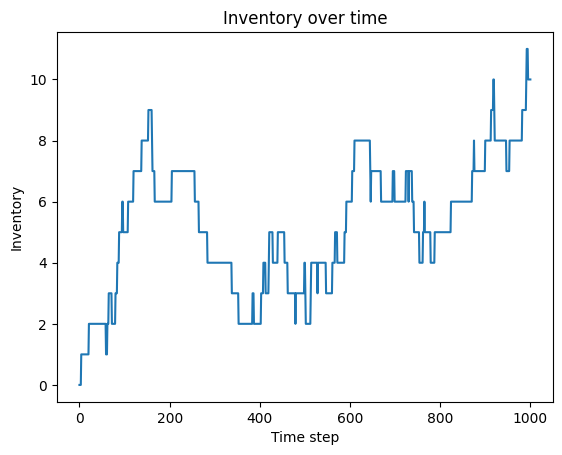

In [8]:
rng = np.random.default_rng(1)

delta = 0.75      # we quote at mid +/- 0.75
S = S0            # current mid-price
q = 0             # inventory (number of shares held)
cash = 0.0        # cash balance

prices = [S]
inventory = [q]

for i in range(n_steps):
    bid = S - delta     # our buy price
    ask = S + delta     # our sell price

    # Someone sells to us: we buy one share at our bid
    if rng.random() < fill_probability(delta):
        q += 1
        cash -= bid

    # Someone buys from us: we sell one share at our ask
    if rng.random() < fill_probability(delta):
        q -= 1
        cash += ask

    # The mid-price moves
    S = S + sigma * np.sqrt(dt) * rng.standard_normal()

    prices.append(S)
    inventory.append(q)

pnl = cash + q * S    # final P&L: cash + value of remaining inventory (mark-to-market)
print("Final inventory:", q)
print("Cash:", cash)
print("P&L:", pnl)

plt.plot(inventory)
plt.title("Inventory over time")
plt.xlabel("Time step")
plt.ylabel("Inventory")
plt.show()

Mean P&L: 66.98585571310032
Std of P&L: 14.62993082043508
P&L Sharpe (mean/std): 4.578685746041568
Std of final inventory: 9.250564726004571


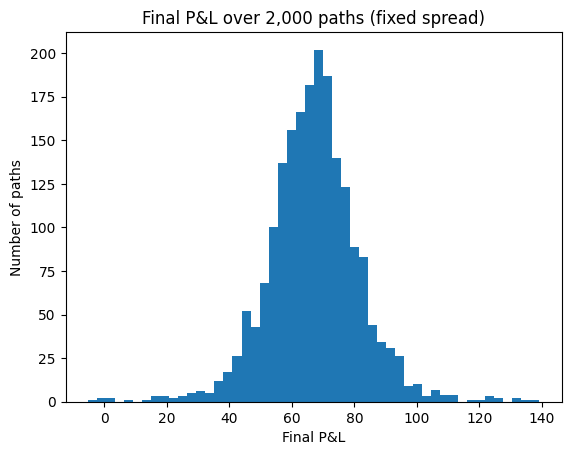

In [9]:
def run_naive(delta, rng):
    """Run one path of the fixed-spread market maker. Returns (final P&L, final inventory)."""
    p_fill = fill_probability(delta)   # constant, since quotes are always at distance delta
    S, q, cash = S0, 0, 0.0
    for i in range(n_steps):
        bid, ask = S - delta, S + delta
        if rng.random() < p_fill:      # someone sells to us
            q += 1
            cash -= bid
        if rng.random() < p_fill:      # someone buys from us
            q -= 1
            cash += ask
        S += sigma * np.sqrt(dt) * rng.standard_normal()
    return cash + q * S, q

rng = np.random.default_rng(2026)
n_paths = 2000
results = [run_naive(0.75, rng) for _ in range(n_paths)]
pnls = np.array([r[0] for r in results])
final_q = np.array([r[1] for r in results])

print("Mean P&L:", pnls.mean())
print("Std of P&L:", pnls.std())
print("P&L Sharpe (mean/std):", pnls.mean() / pnls.std())
print("Std of final inventory:", final_q.std())

plt.hist(pnls, bins=50)
plt.title("Final P&L over 2,000 paths (fixed spread)")
plt.xlabel("Final P&L")
plt.ylabel("Number of paths")
plt.show()

Fixed half-spread: 0.7453852113757117
Fixed spread | mean P&L: 66.5 | std: 14.9 | Sharpe: 4.46 | std final inv: 9.2 | mean max |inv|: 11.1
Avellaneda-Stoikov | mean P&L: 62.1 | std: 7.1 | Sharpe: 8.81 | std final inv: 3.4 | mean max |inv|: 4.6


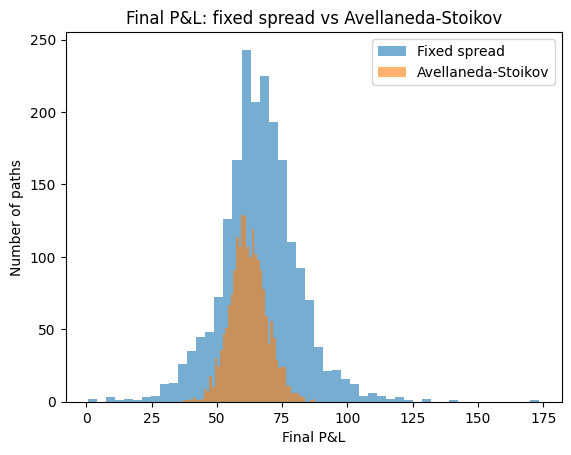

In [10]:
def run_market_maker(strategy, seed, gamma=0.1, delta=0.75):
    """Run one path. strategy is 'naive' or 'as'. Returns (final P&L, final inventory, max |inventory|)."""
    rng = np.random.default_rng(seed)    # same seed => same randomness for both strategies
    S, q, cash = S0, 0, 0.0
    max_abs_q = 0
    for i in range(n_steps):
        t = i * dt
        if strategy == "as":
            reservation = S - q * gamma * sigma**2 * (T - t)
            half_spread = 0.5 * (gamma * sigma**2 * (T - t) + (2 / gamma) * np.log(1 + gamma / k))
            bid, ask = reservation - half_spread, reservation + half_spread
        else:
            bid, ask = S - delta, S + delta

        p_bid = fill_probability(max(S - bid, 0.0))   # distance of our bid below the mid
        p_ask = fill_probability(max(ask - S, 0.0))   # distance of our ask above the mid

        # Always draw the same 3 random numbers per step, whatever the strategy
        u_bid, u_ask, shock = rng.random(), rng.random(), rng.standard_normal()

        if u_bid < p_bid:      # someone sells to us
            q += 1
            cash -= bid
        if u_ask < p_ask:      # someone buys from us
            q -= 1
            cash += ask

        S += sigma * np.sqrt(dt) * shock
        max_abs_q = max(max_abs_q, abs(q))
    return cash + q * S, q, max_abs_q

def summarize(strategy, n_paths=2000, **kwargs):
    results = np.array([run_market_maker(strategy, seed, **kwargs) for seed in range(n_paths)])
    pnl, final_q, max_q = results[:, 0], results[:, 1], results[:, 2]
    return dict(mean=pnl.mean(), std=pnl.std(), sharpe=pnl.mean() / pnl.std(),
                final_inv_std=final_q.std(), mean_max_inv=max_q.mean(), pnl=pnl)

gamma = 0.1
# Fixed half-spread chosen to match the average AS half-spread, so the comparison is fair
delta_fixed = 0.5 * (gamma * sigma**2 * T / 2) + (1 / gamma) * np.log(1 + gamma / k)
print("Fixed half-spread:", delta_fixed)

naive = summarize("naive", delta=delta_fixed)
avst = summarize("as", gamma=gamma)

for name, r in [("Fixed spread", naive), ("Avellaneda-Stoikov", avst)]:
    print(name, "| mean P&L:", round(r["mean"], 1), "| std:", round(r["std"], 1),
          "| Sharpe:", round(r["sharpe"], 2), "| std final inv:", round(r["final_inv_std"], 1),
          "| mean max |inv|:", round(r["mean_max_inv"], 1))

plt.hist(naive["pnl"], bins=50, alpha=0.6, label="Fixed spread")
plt.hist(avst["pnl"], bins=50, alpha=0.6, label="Avellaneda-Stoikov")
plt.title("Final P&L: fixed spread vs Avellaneda-Stoikov")
plt.xlabel("Final P&L")
plt.ylabel("Number of paths")
plt.legend()
plt.show()

Avellaneda-Stoikov (varying gamma):
gamma 0.01 | mean P&L: 66.4 | std: 10.1 | Sharpe: 6.55 | mean max |inv|: 8.2
gamma 0.05 | mean P&L: 64.5 | std: 7.7 | Sharpe: 8.41 | mean max |inv|: 5.6
gamma 0.1 | mean P&L: 62.3 | std: 7.1 | Sharpe: 8.79 | mean max |inv|: 4.6
gamma 0.2 | mean P&L: 57.7 | std: 6.4 | Sharpe: 9.02 | mean max |inv|: 3.8
gamma 0.5 | mean P&L: 45.1 | std: 5.6 | Sharpe: 8.11 | mean max |inv|: 3.0
gamma 1.0 | mean P&L: 29.0 | std: 4.5 | Sharpe: 6.48 | mean max |inv|: 2.5
Fixed spread (varying half-spread):
delta 0.3 | mean P&L: 50.9 | std: 18.0 | Sharpe: 2.83 | mean max |inv|: 15.3
delta 0.5 | mean P&L: 63.5 | std: 15.9 | Sharpe: 4.0 | mean max |inv|: 13.3
delta 0.75 | mean P&L: 66.2 | std: 15.1 | Sharpe: 4.4 | mean max |inv|: 11.1
delta 1.0 | mean P&L: 61.1 | std: 13.5 | Sharpe: 4.52 | mean max |inv|: 9.2
delta 1.5 | mean P&L: 43.4 | std: 10.8 | Sharpe: 4.03 | mean max |inv|: 6.1
delta 2.0 | mean P&L: 27.5 | std: 9.1 | Sharpe: 3.02 | mean max |inv|: 4.1


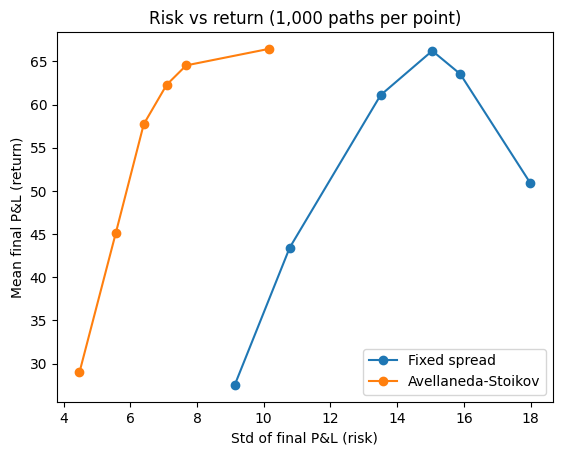

In [11]:
gammas = [0.01, 0.05, 0.1, 0.2, 0.5, 1.0]
deltas = [0.3, 0.5, 0.75, 1.0, 1.5, 2.0]

as_sweep = [summarize("as", n_paths=1000, gamma=g) for g in gammas]
naive_sweep = [summarize("naive", n_paths=1000, delta=d) for d in deltas]

print("Avellaneda-Stoikov (varying gamma):")
for g, r in zip(gammas, as_sweep):
    print("gamma", g, "| mean P&L:", round(r["mean"], 1), "| std:", round(r["std"], 1),
          "| Sharpe:", round(r["sharpe"], 2), "| mean max |inv|:", round(r["mean_max_inv"], 1))

print("Fixed spread (varying half-spread):")
for d, r in zip(deltas, naive_sweep):
    print("delta", d, "| mean P&L:", round(r["mean"], 1), "| std:", round(r["std"], 1),
          "| Sharpe:", round(r["sharpe"], 2), "| mean max |inv|:", round(r["mean_max_inv"], 1))

plt.plot([r["std"] for r in naive_sweep], [r["mean"] for r in naive_sweep], "-o", label="Fixed spread")
plt.plot([r["std"] for r in as_sweep], [r["mean"] for r in as_sweep], "-o", label="Avellaneda-Stoikov")
plt.title("Risk vs return (1,000 paths per point)")
plt.xlabel("Std of final P&L (risk)")
plt.ylabel("Mean final P&L (return)")
plt.legend()
plt.show()

In [12]:
# Sanity check 1: the simulated price volatility should match sigma * sqrt(T)
rng = np.random.default_rng(0)
final_prices = S0 + sigma * np.sqrt(dt) * rng.standard_normal((10000, n_steps)).sum(axis=1)
print("Simulated std of final price:", final_prices.std(), "| theory:", sigma * np.sqrt(T))

# Sanity check 2: a fixed-spread market maker has no directional bias, so mean final inventory ~ 0
print("Mean final inventory (naive, cell 3):", final_q.mean(), "| std error:", final_q.std() / np.sqrt(len(final_q)))

Simulated std of final price: 1.9939493998406137 | theory: 2.0
Mean final inventory (naive, cell 3): 0.0235 | std error: 0.20684891557607937
